In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys

import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

import pyproj
import cmocean

import numpy as np

import src.plotting as plot
import src.utils as utils
from src.config import *

In [3]:
AMOC_ON = "pi/pi-amoc-on"
AMOC_OFF = "pi/pi-amoc-off"

DIR_AMOC_ON = os.path.join(DIR_OUTPUT, AMOC_ON)
DIR_AMOC_OFF = os.path.join(DIR_OUTPUT, AMOC_OFF)

### Preindustrial GIS comparison AMOC-on vs AMOC-off

In [4]:
# Load diagnostic datasets
ds_GIS_amoc_on_ts = xr.open_dataset(os.path.join(DIR_AMOC_ON, "ice_GRL-16KM_ts.nc"), mode="r")
ds_GIS_amoc_off_ts = xr.open_dataset(os.path.join(DIR_AMOC_OFF, "ice_GRL-16KM_ts.nc"), mode="r")

ds_smb_amoc_on_ts = xr.open_dataset(os.path.join(DIR_AMOC_ON, "smb_GRL-16KM_ts.nc"), mode="r")
ds_smb_amoc_off_ts = xr.open_dataset(os.path.join(DIR_AMOC_OFF, "smb_GRL-16KM_ts.nc"), mode="r")

In [5]:
# Load full datasets
ds_GIS_amoc_on = xr.open_dataset(os.path.join(DIR_AMOC_ON, "ice_GRL-16KM.nc"), mode="r")
ds_GIS_amoc_off = xr.open_dataset(os.path.join(DIR_AMOC_OFF, "ice_GRL-16KM.nc"), mode="r")

ds_smb_amoc_on = xr.open_dataset(os.path.join(DIR_AMOC_ON, "smb_GRL-16KM.nc"), mode="r")
ds_smb_amoc_off = xr.open_dataset(os.path.join(DIR_AMOC_OFF, "smb_GRL-16KM.nc"), mode="r")

# Load observation data from Honing et al. (2012)
ds_GIS_obs = xr.open_dataset(os.path.join(DIR_DATA_EXT, "Honing_data", "perf_obs.nc"), mode='r')

In [6]:
# Transform GIS observation coordinates to match the climber coordinates
if ds_GIS_obs.sizes["x"] != ds_GIS_amoc_on.sizes["xc"]:
    raise ValueError("x and xc dimensions have different lengths")
if ds_GIS_obs.sizes["y"] != ds_GIS_amoc_on.sizes["yc"]:
    raise ValueError("y and yc dimensions have different lengths")

ds_GIS_obs = (
    ds_GIS_obs.assign_coords(
        x=("x", ds_GIS_amoc_on["xc"].values),
        y=("y", ds_GIS_amoc_on["yc"].values),
    )
    .rename({"x": "xc", "y": "yc"})
)

ds_GIS_obs

<xarray.Dataset> Size: 618kB
Dimensions:   (yc: 182, xc: 106)
Coordinates:
  * xc        (xc) float32 424B -720.0 -704.0 -688.0 ... 928.0 944.0 960.0
  * yc        (yc) float32 728B -3.45e+03 -3.434e+03 ... -570.0 -554.0
Data variables:
    phi       (yc, xc) float64 154kB ...
    lambda    (yc, xc) float64 154kB ...
    mask_ice  (yc, xc) float64 154kB ...
    z_sur     (yc, xc) float64 154kB ...

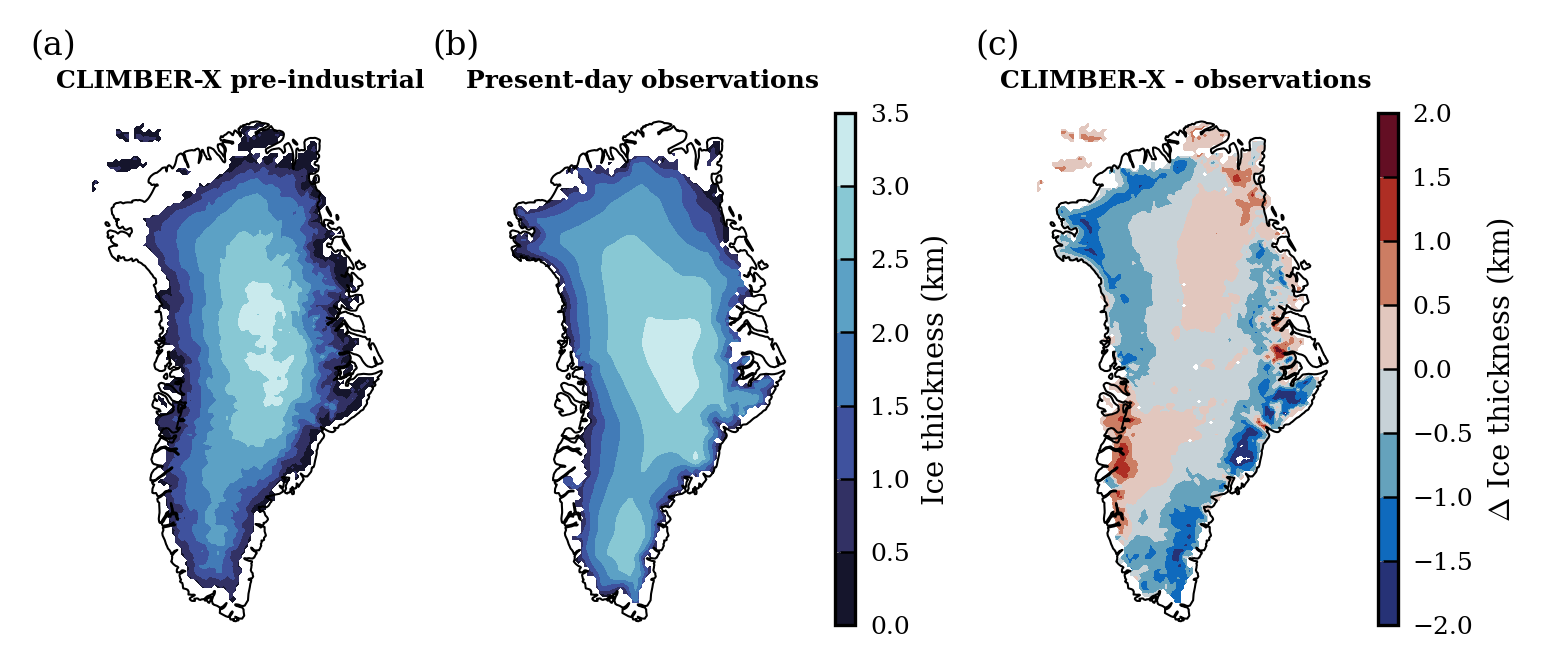

In [7]:
fig = plt.figure(figsize=(0.7*plot.width_twocol, plot.height_onecol), constrained_layout=True,)

proj = ccrs.Stereographic(central_longitude=-45, central_latitude=90, true_scale_latitude=70,)

gs = fig.add_gridspec( nrows=1, ncols=5, width_ratios=[1, 1, 0.06, 1, 0.06])

ax1 = fig.add_subplot(gs[0, 0], projection=proj)
ax2 = fig.add_subplot(gs[0, 1], projection=proj)
ax_cb = fig.add_subplot(gs[0, 2])
ax3 = fig.add_subplot(gs[0, 3], projection=proj)
ax_cb2 = fig.add_subplot(gs[0, 4])

mask = ds_GIS_amoc_on["mask_bed"].isel(time=-1) > 0


_, _, cf1 = plot.plot_GIS_contourf_yelmo(
    ds_GIS_amoc_on,
    "H_ice",
    time_index=-1,
    mask=mask,
    ax=ax1,
    levels=[0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5],
    title="CLIMBER-X pre-industrial",
)

_, _, cf2 = plot.plot_GIS_contourf_yelmo(
    ds_GIS_obs,
    "z_sur",
    mask=mask,
    ax=ax2,
    levels=[0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5],
    title="Present-day observations",
)

ds_GIS_diff = ds_GIS_amoc_on["H_ice"].isel(time=-1) - ds_GIS_obs["z_sur"]
cmap = cmocean.cm.balance  # blue to red divergent
_, _, cf3 = plot.plot_GIS_contourf_yelmo(
    ds_GIS_diff,
    "H_ice",
    mask=None,
    ax=ax3,
    levels=[-2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2],
    cmap=cmap,
    title="CLIMBER-X - observations",
)

cbar1 = fig.colorbar(
    cf1,
    cax=ax_cb,
    orientation='vertical',
    label='Ice thickness (km)',
    extend="both",
)

cbar2 = fig.colorbar(
    cf3,
    cax=ax_cb2,
    orientation='vertical',
    label=r'$\Delta$ Ice thickness (km)',
    extend="both",
)

for ax, label in zip((ax1, ax2, ax3), ("(a)", "(b)", "(c)")):
    ax.text(-0.2, 1.1, label, transform=ax.transAxes, va='bottom', ha='left')

plt.savefig(os.path.join(DIR_FIG, "GrIS_comparison_obs.pdf"), format="pdf")

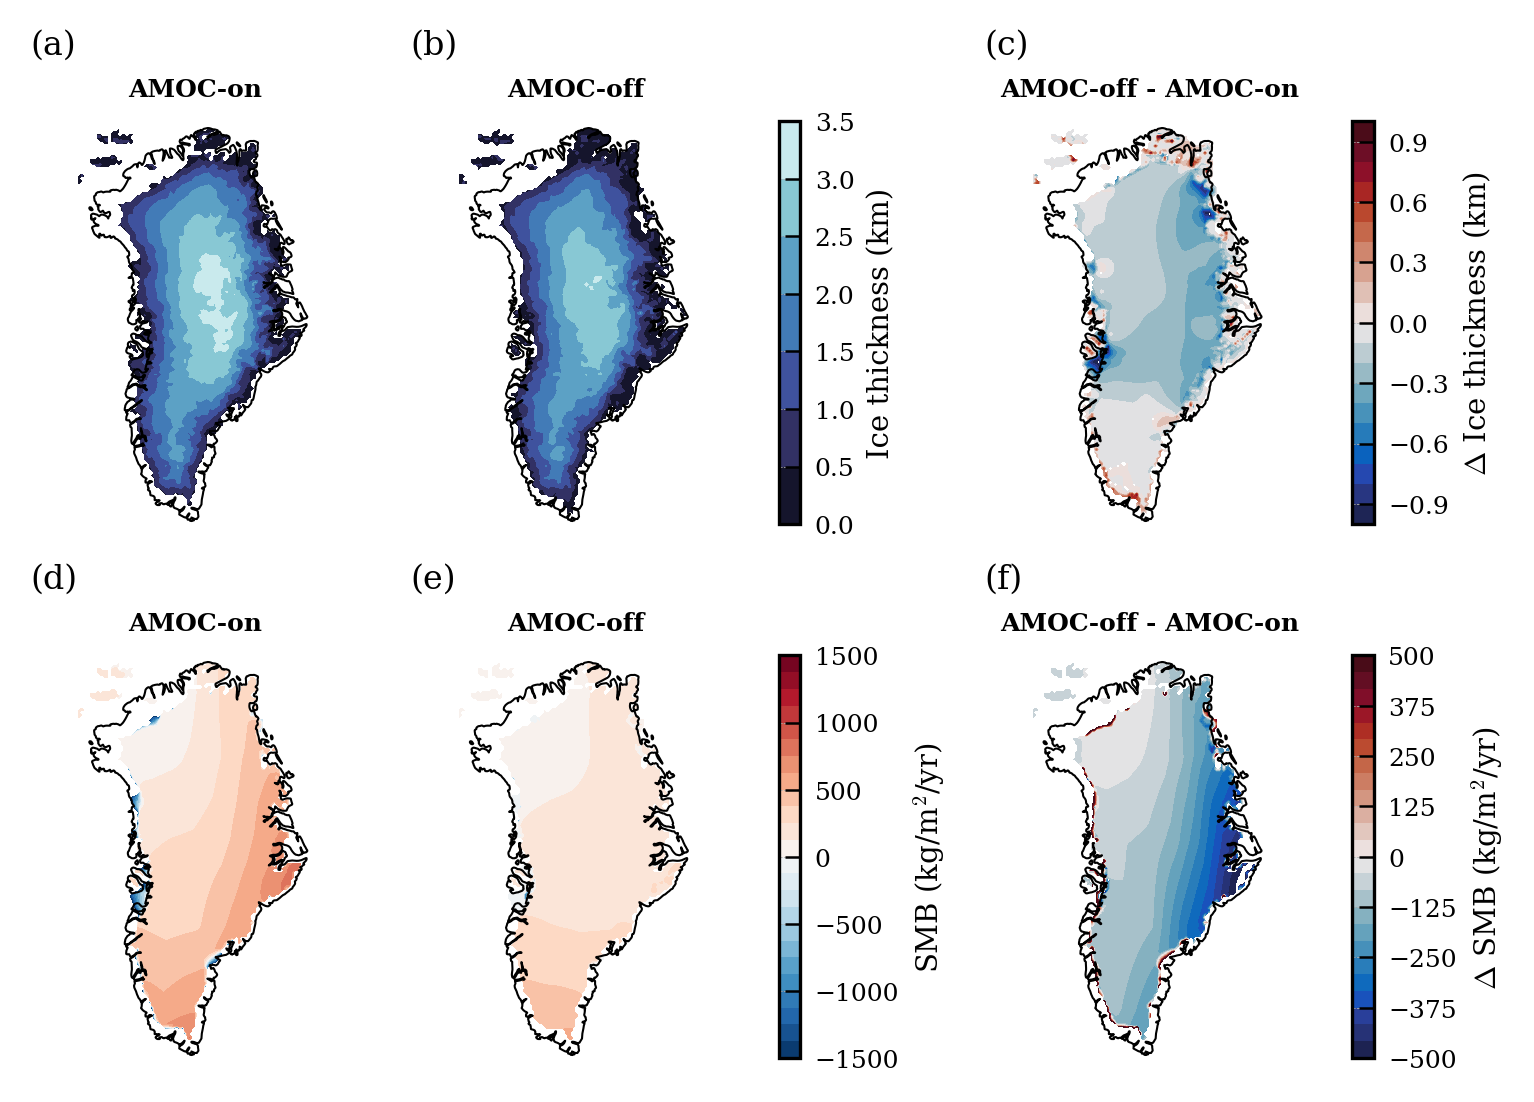

In [8]:
fig = plt.figure(figsize=(0.7*plot.width_twocol, 0.8*plot.height_twocol), constrained_layout=True,)

proj = ccrs.Stereographic(central_longitude=-45, central_latitude=90, true_scale_latitude=70,)

gs = fig.add_gridspec(nrows=2, ncols=5, width_ratios=[1, 1, 0.06, 1, 0.06])

ax1 = fig.add_subplot(gs[0, 0], projection=proj)
ax2 = fig.add_subplot(gs[0, 1], projection=proj)
ax_cb = fig.add_subplot(gs[0, 2])
ax3 = fig.add_subplot(gs[0, 3], projection=proj)
ax_cb2 = fig.add_subplot(gs[0, 4])

ax4 = fig.add_subplot(gs[1, 0], projection=proj)
ax5 = fig.add_subplot(gs[1, 1], projection=proj)
ax_cb3 = fig.add_subplot(gs[1, 2])
ax6 = fig.add_subplot(gs[1, 3], projection=proj)
ax_cb4 = fig.add_subplot(gs[1, 4])

mask = ds_GIS_amoc_on["mask_bed"].isel(time=-1) > 0


# Ice thickness
_, _, cf1 = plot.plot_GIS_contourf_yelmo(
    ds_GIS_amoc_on,
    "H_ice",
    time_index=-1,
    mask=mask,
    ax=ax1,
    levels=[0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5],
    title="AMOC-on",
)

_, _, cf2 = plot.plot_GIS_contourf_yelmo(
    ds_GIS_amoc_off,
    "H_ice",
    time_index=-1,
    mask=mask,
    ax=ax2,
    levels=[0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5],
    title="AMOC-off",
)

ds_GIS_diff = ds_GIS_amoc_off["H_ice"].isel(time=-1) - ds_GIS_amoc_on["H_ice"].isel(time=-1)
cmap = cmocean.cm.balance  # blue to red divergent
_, _, cf3 = plot.plot_GIS_contourf_yelmo(
    ds_GIS_diff,
    "H_ice",
    mask=None,
    ax=ax3,
    levels=list(np.linspace(-1, 1, 21)),
    cmap=cmap,
    title="AMOC-off - AMOC-on",
)

cbar1 = fig.colorbar(
    cf1,
    cax=ax_cb,
    orientation='vertical',
    label='Ice thickness (km)',
    extend="both",
)

cbar2 = fig.colorbar(
    cf3,
    cax=ax_cb2,
    orientation='vertical',
    label=r'$\Delta$ Ice thickness (km)',
    extend="both",
)


# Surface mass balance
mask_smb = ds_smb_amoc_on["mask_ice"].isel(time=-1) > 0

_, _, cf4 = plot.plot_GIS_smb_contourf_yelmo(
    ds_smb_amoc_on,
    "smb_ice",
    time_index=-1,
    mask=mask_smb,
    ax=ax4,
    levels=list(np.linspace(-1500, 1500, 25, endpoint=True)),
    title="AMOC-on",
)

_, _, cf5 = plot.plot_GIS_smb_contourf_yelmo(
    ds_smb_amoc_off,
    "smb_ice",
    time_index=-1,
    mask=mask_smb,
    ax=ax5,
    levels=list(np.linspace(-1500, 1500, 25, endpoint=True)),
    title="AMOC-off",
)

ds_smb_diff = ds_smb_amoc_off["smb_ice"].isel(time=-1) - ds_smb_amoc_on["smb_ice"].isel(time=-1)
cmap = cmocean.cm.balance  # blue to red divergent
_, _, cf6 = plot.plot_GIS_smb_contourf_yelmo(
    ds_smb_diff,
    "smb_ice",
    mask=mask_smb,
    ax=ax6,
    levels=list(np.linspace(-500, 500, 25, endpoint=True)),
    cmap=cmap,
    title="AMOC-off - AMOC-on",
)

cbar3 = fig.colorbar(
    cf4,
    cax=ax_cb3,
    orientation="vertical",
    label="SMB (kg/m$^2$/yr)",
    ticks=[-1500, -1000, -500, 0, 500, 1000, 1500],
    extend="both",
)

cbar4 = fig.colorbar(
    cf6,
    cax=ax_cb4,
    orientation='vertical',
    label=r'$\Delta$ SMB (kg/m$^2$/yr)',
    extend="both",
)


for ax, label in zip((ax1, ax2, ax3, ax4, ax5, ax6), ("(a)", "(b)", "(c)", "(d)", "(e)", "(f)")):
    ax.text(-0.2, 1.15, label, transform=ax.transAxes, va='bottom', ha='left')

plt.savefig(os.path.join(DIR_FIG, "GrIS_comparison_amoc_on_minus_off.pdf"), format="pdf")